In [1]:
import pandas as pd



In [3]:
# Load the four CSV files into Pandas DataFrames.
# These files represent the Store, Employee,
# Product and Sales_Performance tables used in the assignment.
try:
    store_df = pd.read_csv("store.csv")
    employee_df = pd.read_csv("employee.csv")
    product_df = pd.read_csv("product.csv")
    sales_df = pd.read_csv("sales_performance.csv")

    print("All files loaded successfully")

except FileNotFoundError as e:
    print(f"File loading error: {e}")
    

All files loaded successfully


In [4]:
# This is used to perform an initial inspection
# of the dataset and verify that the data loaded correctly.
store_df.head()

,Store_ID,Store_Name,City,Opening_Year
0,1,Store_1,Edmonton,2013
1,2,Store_2,Vancouver,1997
2,3,Store_3,Vancouver,2011
3,4,Store_4,Vancouver,2018
4,5,Store_5,Edmonton,2001


In [5]:
# Display the first 5 records of the Employee table.
# This is used to perform an initial inspection
# of the dataset and verify that the data loaded correctly.
employee_df.head()

,Employee_ID,DOB,DOJ,Store_ID
0,1000,58:57.4,26:22.1,4
1,1001,35:23.1,49:21.7,5
2,1002,15:35.7,14:24.0,8
3,1003,57:19.5,58:31.6,6
4,1004,06:33.9,33:00.9,3


In [6]:
# Display the first 5 records of the Product table.
# This is used to perform an initial inspection
# of the dataset and verify that the data loaded correctly.
product_df.head()

,Product_ID,Category,Base_Price
0,200,Home,19.41
1,201,Home,186.62
2,202,Food,257.09
3,203,Home,263.82
4,204,Home,271.33


In [7]:
# Display the first 5 records of the Sales table.
# This is used to perform an initial inspection
# of the dataset and verify that the data loaded correctly.
sales_df.head()

,Employee_ID,Product_ID,Sale_Date,Units_Sold,Revenue,Effort_Hours
0,1051,204,2024-02-27,7,282.75,11.63
1,1092,231,2024-01-07,9,276.50,7.35
2,1014,223,2024-04-22,3,219.29,5.91
3,1071,218,2024-06-14,8,344.52,11.03
4,1060,211,2024-05-23,6,298.22,10.90


In [8]:
# Display information about each table including:
# number of records, column names, datatypes,
# and non-null values. This is used to identify
# potential data quality issues before performing ETL.
print("STORE")
store_df.info()

print("\nEMPLOYEE")
employee_df.info()

print("\nPRODUCT")
product_df.info()

print("\nSALES")
sales_df.info()

STORE
<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Store_ID      11 non-null     int64
 1   Store_Name    11 non-null     str  
 2   City          11 non-null     str  
 3   Opening_Year  11 non-null     int64
dtypes: int64(2), str(2)
memory usage: 484.0 bytes

EMPLOYEE
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Employee_ID  100 non-null    str  
 1   DOB          100 non-null    str  
 2   DOJ          100 non-null    str  
 3   Store_ID     100 non-null    str  
dtypes: str(4)
memory usage: 3.3 KB

PRODUCT
<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Product_ID  42 non-null     str    
 1   

In [9]:
# Check for duplicate primary key values in each table.
# Primary keys should uniquely identify records and
# duplicate values would violate entity integrity.
print("Store_ID Duplicates:", store_df["Store_ID"].duplicated().sum())

print("Employee_ID Duplicates:", employee_df["Employee_ID"].duplicated().sum())

print("Product_ID Duplicates:", product_df["Product_ID"].duplicated().sum())

Store_ID Duplicates: 0
Employee_ID Duplicates: 0
Product_ID Duplicates: 0


In [10]:
# Validate foreign key relationships between tables.
# The ~ operator means NOT, so these checks will return
# records whose foreign key values do not exist in the
# corresponding parent table.

# Check for Employee records containing invalid Store_ID values.
print("Invalid Employee Store_IDs:")
print(employee_df[
    ~employee_df["Store_ID"].isin(store_df["Store_ID"])
])

# Check for Sales records containing Employee_ID values
# that do not exist in the Employee table.
print("\nInvalid Sales Employee_IDs:")
print(sales_df[
    ~sales_df["Employee_ID"].isin(employee_df["Employee_ID"])
])

# Check for Sales records containing Product_ID values
# that do not exist in the Product table.
# Product_ID is converted to a string datatype to match
# the Product table during validation.
print("\nInvalid Sales Product_IDs:")
print(sales_df[
    ~sales_df["Product_ID"].astype(str).isin(product_df["Product_ID"])
])

Invalid Employee Store_IDs:
   Employee_ID      DOB      DOJ Store_ID
0         1000  58:57.4  26:22.1        4
1         1001  35:23.1  49:21.7        5
2         1002  15:35.7  14:24.0        8
3         1003  57:19.5  58:31.6        6
4         1004  06:33.9  33:00.9        3
..         ...      ...      ...      ...
95        1095  16:09.8  04:07.6        9
96        1096  06:56.0  09:18.8       10
97        1097  47:21.6  55:22.3        7
98        1098  23:47.2  57:33.8        5
99        1099  12:48.6  58:51.6        2

[100 rows x 4 columns]

Invalid Sales Employee_IDs:
      Employee_ID  Product_ID   Sale_Date  Units_Sold  Revenue  Effort_Hours
29           1048         216  2024-03-22           1   299.81          8.87
364          1048         220  2024-01-24           4   198.81          6.39
447          1048         203  2024-06-06           3    93.43          2.01
593          1048         211  2024-01-12           7   353.79          9.22
618          1048         223 

In [11]:
# Check the datatypes of Store_ID in both tables.
# This is used to determine whether datatype mismatches
# may be causing foreign key validation failures.
print(store_df["Store_ID"].dtype)
print(employee_df["Store_ID"].dtype)

int64
str


In [13]:
# Convert Employee Store_ID values from string to integer format.
# This standardizes the datatype so it matches the Store table
# and allows foreign key validation to be performed correctly.
employee_df["Store_ID"] = employee_df["Store_ID"].astype(int)

# Re-run the Employee -> Store foreign key validation.
# An empty DataFrame indicates that all remaining Store_ID
# values exist in the Store table after cleaning
employee_df[
    ~employee_df["Store_ID"].isin(store_df["Store_ID"])
]

ValueError: invalid literal for int() with base 10: 'a'

In [14]:
employee_df["Store_ID"].unique()


<StringArray>
['4', '5', '8', '6', '3', '10', '7', '2', 'a', '9', '1']
Length: 11, dtype: str

In [15]:
# Display the employee record containing the invalid Store_ID value.
# This is used to isolate the offending record and confirm
# the source of the foreign key validation failure.
employee_df[
    employee_df["Store_ID"] == "a"
]

,Employee_ID,DOB,DOJ,Store_ID
23,1023,15:41.0,58:39.3,a


In [16]:
# Remove employee records containing non-numeric Store_ID values.
# The value 'a' was identified during validation and does not
# represent a valid foreign key reference to the Store table.
employee_df = employee_df[
    employee_df["Store_ID"].str.isnumeric()
]

print("Remaining Employee Records:", len(employee_df))

Remaining Employee Records: 99


In [17]:
employee_df["Store_ID"] = employee_df["Store_ID"].astype(int)

employee_df[
    ~employee_df["Store_ID"].isin(store_df["Store_ID"])
]

,Employee_ID,DOB,DOJ,Store_ID


In [18]:
# Check for invalid business values in the Sales table.
# According to the assignment requirements:
# Revenue must be greater than or equal to 0,
# Units_Sold must be greater than or equal to 1,
# and Effort_Hours must be greater than or equal to 0.
print("Negative Revenue Records")
print(sales_df[sales_df["Revenue"] < 0])

print("\nInvalid Units Sold Records")
print(sales_df[sales_df["Units_Sold"] < 1])

print("\nNegative Effort Hours Records")
print(sales_df[sales_df["Effort_Hours"] < 0])

Negative Revenue Records
    Employee_ID  Product_ID   Sale_Date  Units_Sold  Revenue  Effort_Hours
63         1043         235  2024-01-08           5  -284.12          8.25
120        1034         202  2024-04-03           4  -259.00          7.48

Invalid Units Sold Records
Empty DataFrame
Columns: [Employee_ID, Product_ID, Sale_Date, Units_Sold, Revenue, Effort_Hours]
Index: []

Negative Effort Hours Records
    Employee_ID  Product_ID   Sale_Date  Units_Sold  Revenue  Effort_Hours
217        1038         235  2024-03-19           4    73.51         -1.77


In [19]:
# Create a cleaned version of the Sales dataset by removing
# records that violate the business rules identified during
# the data quality validation phase.
sales_clean_df = sales_df[
    (sales_df["Revenue"] >= 0) &
    (sales_df["Units_Sold"] >= 1) &
    (sales_df["Effort_Hours"] >= 0)
]

print("Original Sales Records:", len(sales_df))
print("Clean Sales Records:", len(sales_clean_df))
print("Removed Records:", len(sales_df) - len(sales_clean_df))

Original Sales Records: 20000
Clean Sales Records: 19997
Removed Records: 3


In [20]:
print(store_df.columns)
print(employee_df.columns)
print(product_df.columns)
print(sales_clean_df.columns)

Index(['Store_ID', 'Store_Name', 'City', 'Opening_Year'], dtype='str')
Index(['Employee_ID', 'DOB', 'DOJ', 'Store_ID'], dtype='str')
Index(['Product_ID', 'Category', 'Base_Price'], dtype='str')
Index(['Employee_ID', 'Product_ID', 'Sale_Date', 'Units_Sold', 'Revenue',
       'Effort_Hours'],
      dtype='str')


In [21]:
# Convert key identifier columns to integer datatypes.
# This standardizes the datatypes across related tables
# so joins can be performed correctly during the ETL phase.
product_df["Product_ID"] = product_df["Product_ID"].astype(int)
employee_df["Employee_ID"] = employee_df["Employee_ID"].astype(int)
sales_clean_df["Employee_ID"] = sales_clean_df["Employee_ID"].astype(int)

ValueError: invalid literal for int() with base 10: 'bc31'

In [22]:
product_df["Product_ID"].unique()

<StringArray>
[ '200',  '201',  '202',  '203',  '204',  '205',  '206',  '207',  '208',
  '209',  '210',  '211',  '212',  '213',  '214',  '215',  '216',  '217',
  '218',  '219',  '220',  '221',  '222',  '223',  '224',  '225',  '226',
  '227',  '228',  '229',  '230',  '231',  '232',  '233',  '234',  '235',
  '236',  '237',  '238',  '239', 'bc31',  '999']
Length: 42, dtype: str

In [23]:
# Display Product records containing non-numeric Product_ID values.
# This validation is performed before datatype conversion to identify
# malformed identifier values that could interfere with ETL processing
product_df[
    ~product_df["Product_ID"].str.isnumeric()
]

,Product_ID,Category,Base_Price
40,bc31,Other,111.0


In [24]:
# Remove Product records containing non-numeric Product_ID values.
# The invalid Product_ID value 'bc31' was identified during
# validation and removed before datatype standardization.
product_df = product_df[
    product_df["Product_ID"].str.isnumeric()
]

print("Remaining Product Records:", len(product_df))

Remaining Product Records: 41


In [25]:
# Convert Product_ID values to an integer datatype after cleaning.
# This standardizes the Product_ID column so it matches the Sales table
# and can be used reliably during ETL joins.
product_df["Product_ID"] = product_df["Product_ID"].astype(int)

In [26]:
print(product_df["Product_ID"].dtype)

int64


In [27]:
# Search for Employee_ID 1048 in the Employee table.
# This investigation was performed after foreign key validation
# identified Sales records referencing Employee_ID 1048.
# An empty result indicates that the employee record does not exist.
employee_df[
    employee_df["Employee_ID"] == "1048"
]

,Employee_ID,DOB,DOJ,Store_ID


In [28]:
employee_df[
    employee_df["Employee_ID"] == 1048
]

,Employee_ID,DOB,DOJ,Store_ID


In [29]:
# Remove Sales records containing Employee_ID values that do not
# exist in the Employee table. These records were identified during
# foreign key validation and violate referential integrity.
sales_clean_df = sales_clean_df[
    sales_clean_df["Employee_ID"].isin(employee_df["Employee_ID"].astype(str))
]

print("Remaining Sales Records:", len(sales_clean_df))

Remaining Sales Records: 19604


In [30]:
# Check for remaining Sales records containing Employee_ID values
# that do not exist in the Employee table. The ~ operator returns
# records that fail the foreign key validation check.
invalid_employee_sales = sales_clean_df[
    ~sales_clean_df["Employee_ID"].isin(employee_df["Employee_ID"])
]

print("Invalid Employee References:", len(invalid_employee_sales))

Invalid Employee References: 0


In [31]:
# Convert Employee_ID columns to integer datatypes after cleaning.
# This datatype standardization ensures that the Employee and Sales
# tables use matching key formats before performing ETL joins.
employee_df["Employee_ID"] = employee_df["Employee_ID"].astype(int)

sales_clean_df["Employee_ID"] = sales_clean_df["Employee_ID"].astype(int)

ValueError: invalid literal for int() with base 10: 'A69'

In [33]:
# Display records containing non-numeric identifier values.
# These checks were performed before datatype conversion to identify
# malformed primary and foreign key values within the datasets
employee_df[
    ~employee_df["Employee_ID"].str.isnumeric()
]
product_df[
    ~product_df["Product_ID"].str.isnumeric()
]
employee_df[
    ~employee_df["Store_ID"].astype(str).str.isnumeric()
]

AttributeError: Can only use .str accessor with string values, not integer

In [34]:
employee_df[
    ~employee_df["Employee_ID"].str.isnumeric()
]

,Employee_ID,DOB,DOJ,Store_ID
48,A69,58:54.0,12:17.4,7


In [35]:
employee_df = employee_df[
    employee_df["Employee_ID"].str.isnumeric()
]

print("Remaining Employee Records:", len(employee_df))

Remaining Employee Records: 98


In [36]:
employee_df["Employee_ID"] = employee_df["Employee_ID"].astype(int)

print(employee_df["Employee_ID"].dtype)

int64


In [37]:
print(employee_df["Employee_ID"].dtype)
print(employee_df["Store_ID"].dtype)
print(product_df["Product_ID"].dtype)
print(sales_clean_df["Product_ID"].dtype)
print(sales_clean_df["Employee_ID"].dtype)

int64
int64
int64
int64
str


In [38]:
sales_clean_df["Employee_ID"] = sales_clean_df["Employee_ID"].astype(int)

print(sales_clean_df["Employee_ID"].dtype)

int64


In [39]:
print(employee_df["Employee_ID"].dtype)
print(employee_df["Store_ID"].dtype)
print(product_df["Product_ID"].dtype)
print(sales_clean_df["Product_ID"].dtype)
print(sales_clean_df["Employee_ID"].dtype)

int64
int64
int64
int64
int64


In [40]:
# Merge the cleaned Sales, Employee, Store, and Product tables
# into a single analytical dataset. This transformed dataset
# combines transactional, employee, store, and product information
# and will be used for descriptive analytics and predictive analytics.

# Join Sales and Employee using Employee_ID.
etl_df = sales_clean_df.merge(
    employee_df,
    on="Employee_ID"
)

# Join the resulting dataset with Store information using Store_ID.
etl_df = etl_df.merge(
    store_df,
    on="Store_ID"
)

# Join the resulting dataset with Product information using Product_ID.
etl_df = etl_df.merge(
    product_df,
    on="Product_ID"
)

In [41]:
# Display the dimensions and sample records of the transformed dataset.
# The shape function shows the number of rows and columns after the ETL process,
# while head() displays the first few records to verify that the joins succeeded
print(etl_df.shape)
etl_df.head()

(19604, 14)


,Employee_ID,Product_ID,Sale_Date,Units_Sold,Revenue,Effort_Hours,DOB,DOJ,Store_ID,Store_Name,City,Opening_Year,Category,Base_Price
0,1051,204,2024-02-27,7,282.75,11.63,34:28.8,38:32.7,9,Store_9,Edmonton,2010,Home,271.33
1,1092,231,2024-01-07,9,276.50,7.35,35:13.3,33:17.2,4,Store_4,Vancouver,2018,Clothing,153.16
2,1014,223,2024-04-22,3,219.29,5.91,45:38.2,46:22.7,5,Store_5,Edmonton,2001,Clothing,275.71
3,1071,218,2024-06-14,8,344.52,11.03,47:12.8,48:02.7,4,Store_4,Vancouver,2018,Electronics,290.42
4,1060,211,2024-05-23,6,298.22,10.90,33:02.4,34:39.8,7,Store_7,Vancouver,2008,Electronics,101.95


In [42]:
# Save the transformed dataset to a CSV file.
# This preserves the final ETL output after all
# cleaning and transformation steps have been completed.
etl_df.to_csv("transformed_dataset.csv", index=False)

print("Transformed dataset saved successfully.")

Transformed dataset saved successfully.


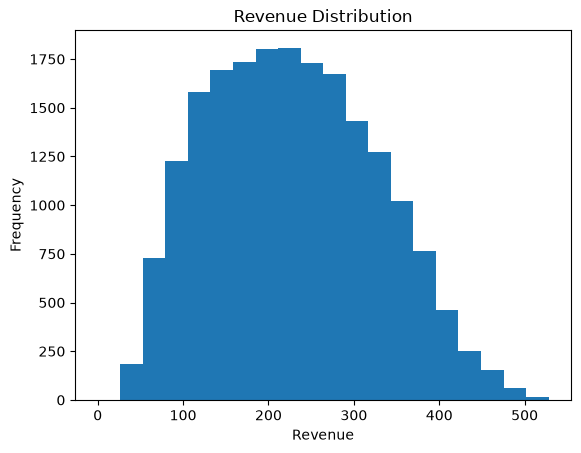

In [43]:
# Import Matplotlib for creating visualizations and charts.
import matplotlib.pyplot as plt

# Create a histogram showing the distribution of revenue values.
# Twenty bins are used to group revenue into ranges, allowing
# the frequency of different revenue amounts to be visualized.
plt.hist(etl_df["Revenue"], bins=20)
plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.show()

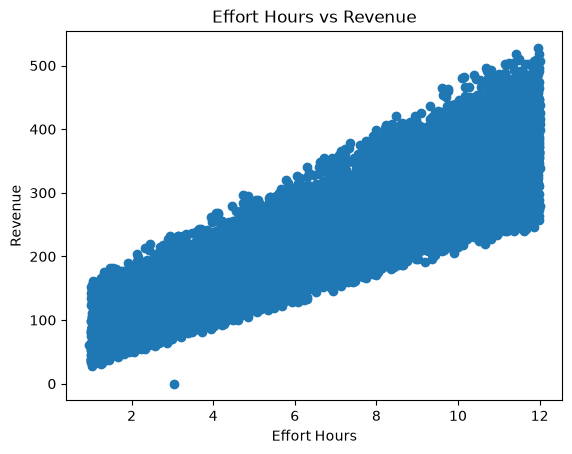

In [44]:
# Create a scatter plot to visualize the relationship between
# Effort_Hours and Revenue. This chart helps determine whether
# an increase in effort hours is associated with an increase in revenue.
plt.scatter(
    etl_df["Effort_Hours"],
    etl_df["Revenue"]
)

# Add a chart title and axis labels to improve readability.
plt.title("Effort Hours vs Revenue")
plt.xlabel("Effort Hours")
plt.ylabel("Revenue")
plt.show()

In [45]:
# Calculate the total revenue generated by each store.
etl_df.groupby("Store_Name")["Revenue"].sum()

Store_Name
Store_1     234717.24
Store_10    653085.16
Store_2     601410.28
Store_3     451535.40
Store_4     639087.43
Store_5     232399.17
Store_6     288563.43
Store_7     519567.73
Store_8     404529.72
Store_9     456025.06
Name: Revenue, dtype: float64

In [46]:
# Import the LinearRegression model for predictive analysis
# Unfinished creating the model in time
from sklearn.linear_model import LinearRegression



Slope: 27.41062458433284
Intercept: 50.48069835045726
